# Loading Dataset

In [1]:
# Day 17 – Cell 1
# Imports and device setup

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
# Day 17 – Cell 2
# Dataset path

from google.colab import drive

drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"

V1_PATH = os.path.join(
    DATASET_PATH,
    "processed_dataset_v1"
)

print("Dataset path:")
print(V1_PATH)

print("\nFiles available:")
print(os.listdir(V1_PATH))

Mounted at /content/drive
Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1

Files available:
['sequences_v1.npz', 'processing_info_v1.json', 'feature_scaler_v1.pkl', 'gru_best_model.pth', 'tcn_best_model.pth', 'lstm_best_model.pth', 'day17_tcn_best_soh_model.pth', 'day15_lstm_best_soh_model.pth', 'day16_gru_best_soh_model.pth']


In [3]:
# Day 17 – Cell 3
# Load sequence dataset

SEQUENCES_PATH = os.path.join(
    V1_PATH,
    "sequences_v1.npz"
)

data = np.load(
    SEQUENCES_PATH,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("Dataset loaded successfully.")
print()

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Dataset loaded successfully.

X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


# Normalizing

In [4]:
# Day 17 – Cell 4
# Normalize SoH

print("Original SoH")
print("------------")

print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

y_soh = y_soh / 100.0

print("\nNormalized SoH")
print("-------------")

print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

Original SoH
------------
Minimum: 0.0
Maximum: 100.0
Mean: 72.7266383162617

Normalized SoH
-------------
Minimum: 0.0
Maximum: 1.0
Mean: 0.7272663831626169


In [5]:
# Day 17 – Cell 5

train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:")
print("X:", X_train.shape)
print("SoH:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("SoH:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("SoH:", y_test.shape)

Train:
X: (1516, 10, 2)
SoH: (1516,)

Validation:
X: (379, 10, 2)
SoH: (379,)

Test:
X: (392, 10, 2)
SoH: (392,)


In [6]:
# Day 17 – Cell 6

BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created.")
print("Batch size:", BATCH_SIZE)

DataLoaders created.
Batch size: 32


# TCN MODEL

In [7]:
# Day 17 – Cell 7
# Define TCN model

class Chomp1d(nn.Module):

    def __init__(self, chomp_size):
        super().__init__()

        self.chomp_size = chomp_size

    def forward(self, x):

        if self.chomp_size > 0:
            return x[:, :, :-self.chomp_size]

        return x


class TemporalBlock(nn.Module):

    def __init__(
        self,
        in_ch,
        out_ch,
        kernel_size,
        dilation,
        dropout=0.2
    ):
        super().__init__()

        padding = (
            kernel_size - 1
        ) * dilation

        self.conv1 = nn.Conv1d(
            in_ch,
            out_ch,
            kernel_size,
            padding=padding,
            dilation=dilation
        )

        self.chomp1 = Chomp1d(
            padding
        )

        self.relu1 = nn.ReLU()

        self.drop1 = nn.Dropout(
            dropout
        )

        self.conv2 = nn.Conv1d(
            out_ch,
            out_ch,
            kernel_size,
            padding=padding,
            dilation=dilation
        )

        self.chomp2 = Chomp1d(
            padding
        )

        self.relu2 = nn.ReLU()

        self.drop2 = nn.Dropout(
            dropout
        )

        self.downsample = (
            nn.Conv1d(
                in_ch,
                out_ch,
                kernel_size=1
            )
            if in_ch != out_ch
            else None
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        out = self.conv1(x)

        out = self.chomp1(out)

        out = self.relu1(out)

        out = self.drop1(out)

        out = self.conv2(out)

        out = self.chomp2(out)

        out = self.relu2(out)

        out = self.drop2(out)

        if self.downsample is None:
            residual = x
        else:
            residual = self.downsample(x)

        return self.relu(
            out + residual
        )


class PrognosticTCN(nn.Module):

    def __init__(
        self,
        input_dim,
        seq_len,
        output_dim=1,
        channels=(96, 96, 64),
        kernel_size=3,
        dropout=0.2
    ):
        super().__init__()

        layers = []

        in_ch = input_dim

        for i, out_ch in enumerate(channels):

            dilation = 2 ** i

            layers.append(
                TemporalBlock(
                    in_ch,
                    out_ch,
                    kernel_size,
                    dilation,
                    dropout
                )
            )

            in_ch = out_ch

        self.tcn = nn.Sequential(
            *layers
        )

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(
            channels[-1] * seq_len,
            64
        )

        self.relu = nn.ReLU()

        self.dropout = nn.Dropout(
            dropout
        )

        self.fc2 = nn.Linear(
            64,
            output_dim
        )

    def forward(self, x):

        # (batch, sequence, features)
        # → (batch, features, sequence)

        x = x.transpose(1, 2)

        x = self.tcn(x)

        x = self.flatten(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.dropout(x)

        x = self.fc2(x)

        return x.squeeze(-1)


seq_len = X_train.shape[1]

input_dim = X_train.shape[2]

model = PrognosticTCN(
    input_dim=input_dim,
    seq_len=seq_len,
    output_dim=1
).to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)

print("\nTrainable parameters:", num_params)

PrognosticTCN(
  (tcn): Sequential(
    (0): TemporalBlock(
      (conv1): Conv1d(2, 96, kernel_size=(3,), stride=(1,), padding=(2,))
      (chomp1): Chomp1d()
      (relu1): ReLU()
      (drop1): Dropout(p=0.2, inplace=False)
      (conv2): Conv1d(96, 96, kernel_size=(3,), stride=(1,), padding=(2,))
      (chomp2): Chomp1d()
      (relu2): ReLU()
      (drop2): Dropout(p=0.2, inplace=False)
      (downsample): Conv1d(2, 96, kernel_size=(1,), stride=(1,))
      (relu): ReLU()
    )
    (1): TemporalBlock(
      (conv1): Conv1d(96, 96, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      (chomp1): Chomp1d()
      (relu1): ReLU()
      (drop1): Dropout(p=0.2, inplace=False)
      (conv2): Conv1d(96, 96, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      (chomp2): Chomp1d()
      (relu2): ReLU()
      (drop2): Dropout(p=0.2, inplace=False)
      (relu): ReLU()
    )
    (2): TemporalBlock(
      (conv1): Conv1d(96, 64, kernel_size=(3,), stride=(1,), padding=(8,

# Training TCN Model

In [8]:
# Day 17 – Cell 8
# Train TCN

NUM_EPOCHS = 30

best_val_loss = float("inf")

train_losses = []
val_losses = []
val_maes = []

CHECKPOINT_PATH = os.path.join(
    V1_PATH,
    "day17_tcn_best_soh_model.pth"
)

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # =========================
    # Training
    # =========================

    model.train()

    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(
            X_batch
        )

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        running_train_loss += (
            loss.item()
            * X_batch.size(0)
        )

    train_loss = (
        running_train_loss
        / len(train_loader.dataset)
    )

    # =========================
    # Validation
    # =========================

    model.eval()

    running_val_loss = 0.0

    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(
                X_batch
            )

            loss = criterion(
                predictions,
                y_batch
            )

            running_val_loss += (
                loss.item()
                * X_batch.size(0)
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                y_batch.cpu().numpy()
            )

    val_loss = (
        running_val_loss
        / len(val_loader.dataset)
    )

    val_mae = mean_absolute_error(
        val_targets,
        val_predictions
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_maes.append(val_mae)

    # =========================
    # Save Best Model
    # =========================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

    # =========================
    # Print
    # =========================

    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val MAE: {val_mae:.6f}"
    )

runtime = time.time() - start_time

print("\nTraining completed.")

print(
    "Best Validation Loss:",
    best_val_loss
)

print(
    "Training Time:",
    round(runtime, 2),
    "seconds"
)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

Epoch 01/30 | Train Loss: 0.081270 | Val Loss: 0.057049 | Val MAE: 0.182953
Epoch 02/30 | Train Loss: 0.058063 | Val Loss: 0.064827 | Val MAE: 0.199385
Epoch 03/30 | Train Loss: 0.055648 | Val Loss: 0.061991 | Val MAE: 0.187514
Epoch 04/30 | Train Loss: 0.055738 | Val Loss: 0.082799 | Val MAE: 0.242539
Epoch 05/30 | Train Loss: 0.052668 | Val Loss: 0.064230 | Val MAE: 0.195776
Epoch 06/30 | Train Loss: 0.053284 | Val Loss: 0.078496 | Val MAE: 0.237170
Epoch 07/30 | Train Loss: 0.051626 | Val Loss: 0.060059 | Val MAE: 0.179792
Epoch 08/30 | Train Loss: 0.050428 | Val Loss: 0.062395 | Val MAE: 0.184689
Epoch 09/30 | Train Loss: 0.050918 | Val Loss: 0.057516 | Val MAE: 0.181384
Epoch 10/30 | Train Loss: 0.051062 | Val Loss: 0.071155 | Val MAE: 0.227432
Epoch 11/30 | Train Loss: 0.050256 | Val Loss: 0.058981 | Val MAE: 0.181153
Epoch 12/30 | Train Loss: 0.048829 | Val Loss: 0.054418 | Val MAE: 0.163322
Epoch 13/30 | Train Loss: 0.046827 | Val Loss: 0.065692 | Val MAE: 0.193151
Epoch 14/30 

In [9]:
# Day 17 – Cell 9
# Load best checkpoint

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

model.eval()

print("Best TCN model loaded successfully.")
print("Best Validation Loss:", best_val_loss)

Best TCN model loaded successfully.
Best Validation Loss: 0.05441783468845966


# Evaluation Metrics

In [14]:
# Day 17 – Cell 10
# Evaluate TCN on test set + inference time

predictions = []
actuals = []

model.eval()

# Start inference timer
inference_start_time = time.time()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(
            X_batch
        )

        predictions.extend(
            outputs.cpu().numpy()
        )

        actuals.extend(
            y_batch.numpy()
        )

# End inference timer
inference_time_tcn = time.time() - inference_start_time

actuals = np.array(actuals)
predictions = np.array(predictions)

print(f"Inference Time: {inference_time_tcn:.4f} seconds")
print(f"Test Samples: {len(actuals)}")

mae_tcn = mean_absolute_error(
    actuals,
    predictions
)

rmse_tcn = np.sqrt(
    mean_squared_error(
        actuals,
        predictions
    )
)

# MAPE for SoH >= 0.20
mape_threshold = 0.20

mask_tcn = actuals >= mape_threshold

mape_tcn = np.mean(
    np.abs(
        (actuals[mask_tcn] - predictions[mask_tcn])
        / actuals[mask_tcn]
    )
) * 100

r2_tcn = r2_score(
    actuals,
    predictions
)

print("\nTCN Test Set Performance")
print("=" * 35)

print(f"MAE  : {mae_tcn:.6f}")
print(f"RMSE : {rmse_tcn:.6f}")
print(f"MAPE : {mape_tcn:.4f}%")
print(f"R²   : {r2_tcn:.6f}")

print(f"\nMAPE threshold : SoH >= {mape_threshold}")
print(f"Samples used   : {np.sum(mask_tcn)} / {len(actuals)}")
print(f"Inference Time : {inference_time_tcn:.4f} seconds")

Inference Time: 0.6916 seconds
Test Samples: 392

TCN Test Set Performance
MAE  : 0.135544
RMSE : 0.184418
MAPE : 18.5418%
R²   : -0.425590

MAPE threshold : SoH >= 0.2
Samples used   : 383 / 392
Inference Time : 0.6916 seconds


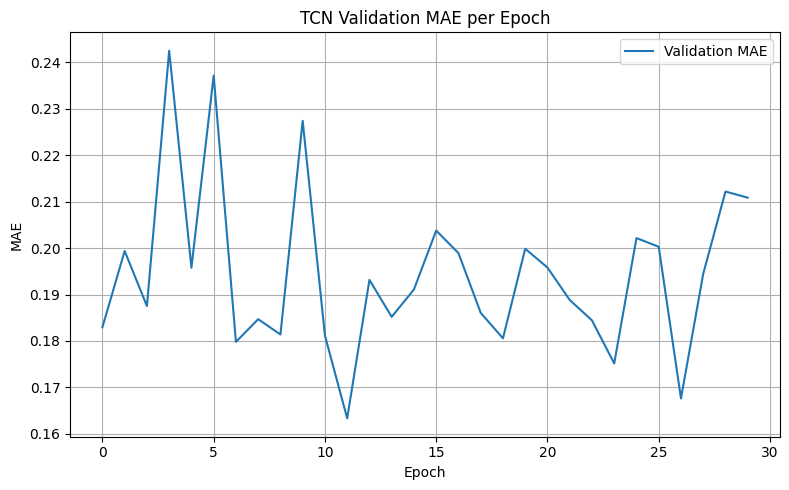

In [11]:
# Day 17 – Cell 12
# Validation MAE per Epoch

plt.figure(figsize=(8, 5))

plt.plot(
    val_maes,
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")

plt.title(
    "TCN Validation MAE per Epoch"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

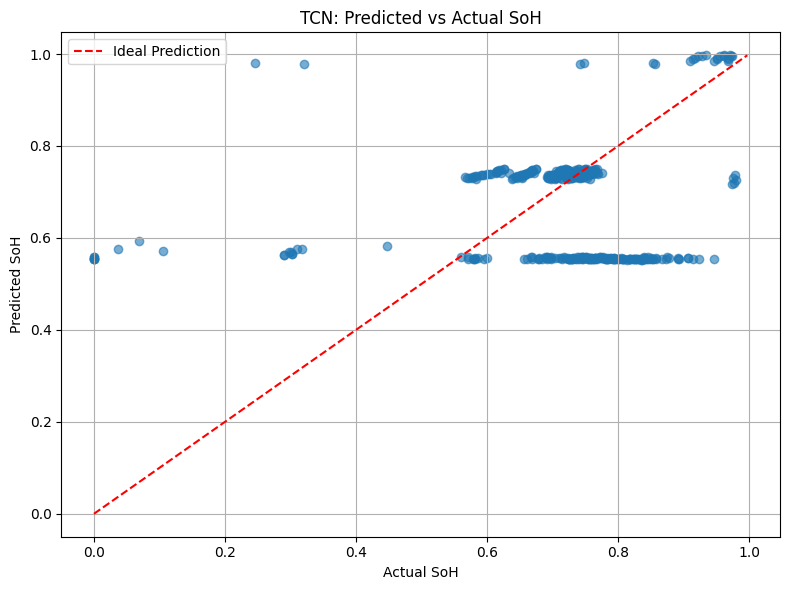

In [12]:
# Day 17 – Cell 13
# TCN Predicted vs Actual SoH

plt.figure(figsize=(8, 6))

plt.scatter(
    actuals,
    predictions,
    alpha=0.6
)

min_val = min(
    actuals.min(),
    predictions.min()
)

max_val = max(
    actuals.max(),
    predictions.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title(
    "TCN: Predicted vs Actual SoH"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.show()

# TCN Summary

In [13]:
# Day 17 – Cell 15
# TCN Model Summary

print("TCN MODEL SUMMARY")
print("=" * 40)

print("Input Features:", input_dim)
print("Sequence Length:", seq_len)

print("Channels:", (96, 96, 64))
print("Kernel Size:", 3)
print("Dilations:", (1, 2, 4))
print("Dropout:", 0.2)

print("Batch Size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

print("\nTrainable Parameters:", num_params)

print("\nBest Validation Loss:")
print(best_val_loss)

print("\nTest Performance")
print("----------------")

print("MAE :", mae_tcn)
print("RMSE:", rmse_tcn)
print("MAPE:", mape_tcn)
print("R²  :", r2_tcn)

print("\nTraining Time:", runtime, "seconds")

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

TCN MODEL SUMMARY
Input Features: 2
Sequence Length: 10
Channels: (96, 96, 64)
Kernel Size: 3
Dilations: (1, 2, 4)
Dropout: 0.2
Batch Size: 32
Epochs: 30

Trainable Parameters: 162337

Best Validation Loss:
0.05441783468845966

Test Performance
----------------
MAE : 0.1355435699224472
RMSE: 0.18441802508834557
MAPE: 875.2401
R²  : -0.4255896806716919

Training Time: 42.91119146347046 seconds

Checkpoint:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/day17_tcn_best_soh_model.pth
